# African Telecom Stocks: A Time Series Analysis

Comparing **Airtel Africa**, **MTN Group** and **Vodacom** (2020 to 2025) with Pandas time series tools, plus a local snapshot of **TNM vs Airtel Malawi** from the Malawi Stock Exchange (MSE) Q3 2026 report.

**Tools:** Python, Pandas, yfinance, Matplotlib, Jupyter Notebook

**Why these tickers?** yfinance does not carry MSE-listed shares (TNM, Airtel Malawi). Airtel Malawi's parent, Airtel Africa, trades in London, and MTN and Vodacom are the two largest listed telecoms on the Johannesburg exchange, so they give a daily price history for the same industry.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

plt.rcParams.update({"figure.figsize": (12, 5), "axes.grid": True, "grid.alpha": 0.3})

TICKERS = {"AAF.L": "Airtel Africa", "MTN.JO": "MTN Group", "VOD.JO": "Vodacom"}
START, END = "2020-01-01", "2025-12-31"

## 1. Download the data

In [2]:
frames = {}
for ticker, name in TICKERS.items():
    df = yf.Ticker(ticker).history(start=START, end=END, auto_adjust=True)
    df.index = df.index.tz_localize(None)       # drop timezone for clean plotting
    df.index.name = "Date"
    frames[name] = df[["Open", "High", "Low", "Close", "Volume"]]
    print(f"{name:14s} {ticker:7s} rows: {len(df):5d}  {df.index.min().date()} -> {df.index.max().date()}")

frames["Airtel Africa"].head()

Airtel Africa  AAF.L   rows:  1514  2020-01-02 -> 2025-12-30
MTN Group      MTN.JO  rows:  1499  2020-01-02 -> 2025-12-30
Vodacom        VOD.JO  rows:  1499  2020-01-02 -> 2025-12-30


,Open,High,Low,Close,Volume
Date,,,,,
2020-01-02,76.254980,80.444271,76.254980,78.598991,1086111
2020-01-03,78.997963,79.297200,77.152683,78.299751,995180
2020-01-06,79.696191,79.720132,76.105376,78.249886,894623
2020-01-07,76.803589,79.496699,76.703845,79.097725,1073498
2020-01-08,78.349629,78.499240,77.003066,77.551666,814587


## 2. Dates as the index
Each DataFrame already uses `Date` as a `DatetimeIndex`. Confirm it and check for gaps or missing values.

In [3]:
for name, df in frames.items():
    assert isinstance(df.index, pd.DatetimeIndex) and df.index.is_monotonic_increasing
    print(name, "| missing values:", int(df.isna().sum().sum()))

Airtel Africa | missing values: 0
MTN Group | missing values: 0
Vodacom | missing values: 0


## 3. Closing prices over time
Prices are in different currencies (pence and South African cents), so raw levels are not directly comparable. The second chart rebases each to 100 at the start.

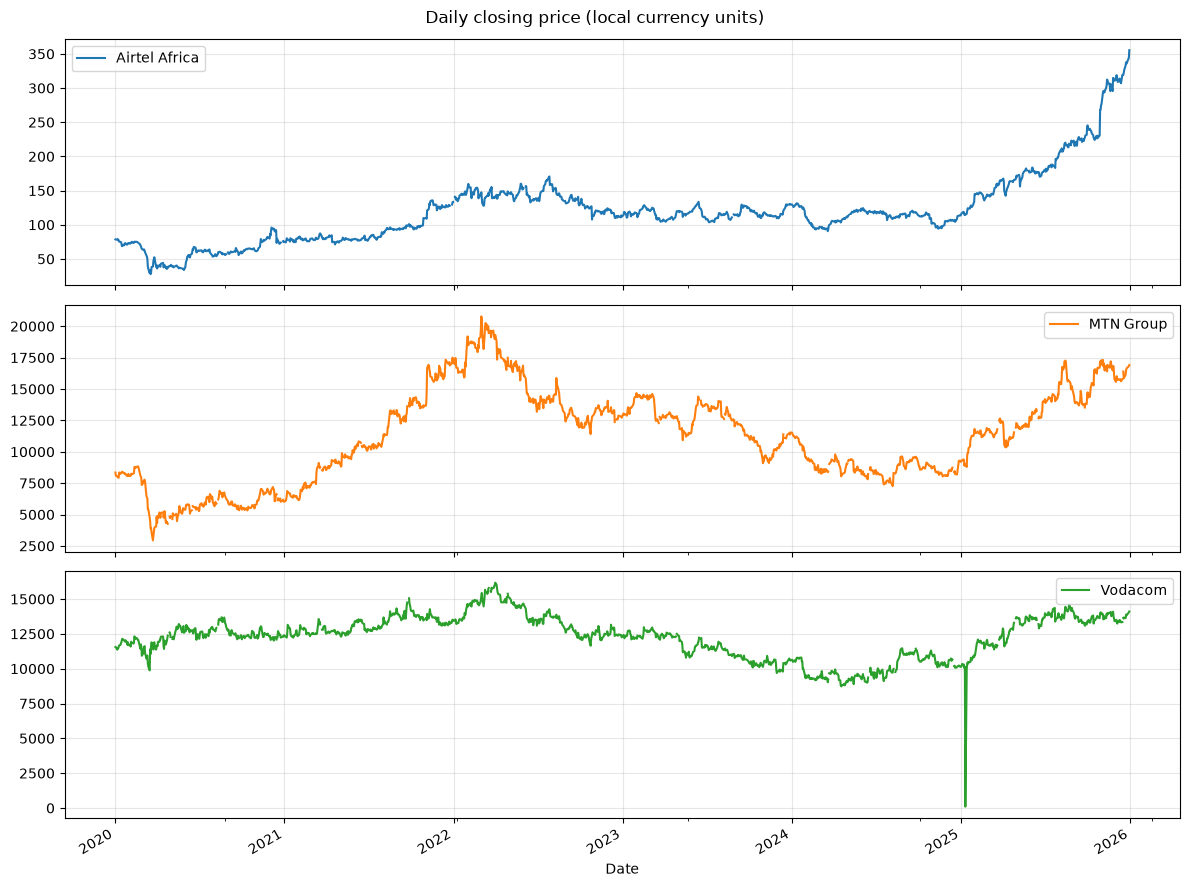

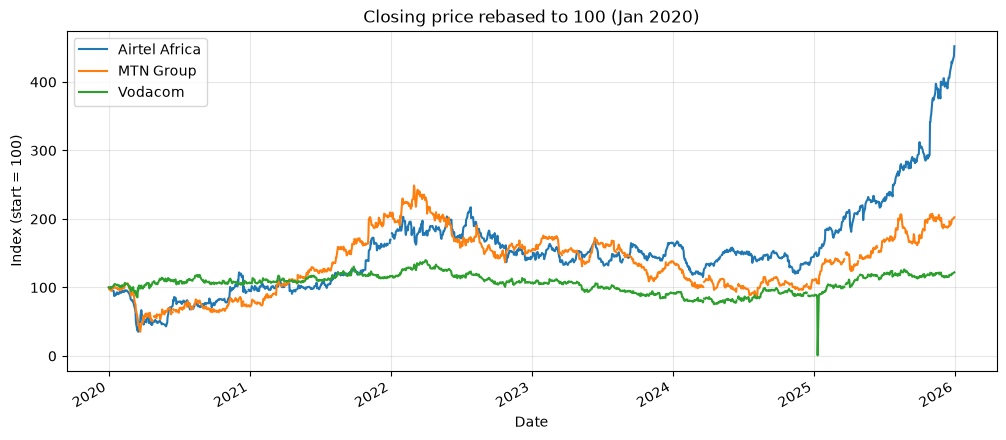

In [4]:
close = pd.DataFrame({name: df["Close"] for name, df in frames.items()})

close.plot(subplots=True, figsize=(12, 9), title="Daily closing price (local currency units)")
plt.tight_layout(); plt.show()

rebased = close / close.bfill().iloc[0] * 100
rebased.plot(title="Closing price rebased to 100 (Jan 2020)")
plt.ylabel("Index (start = 100)"); plt.show()

## 4. Resampling: weekly and monthly
`.resample()` turns daily data into longer-horizon trends. Closing price uses the last observation of each period.

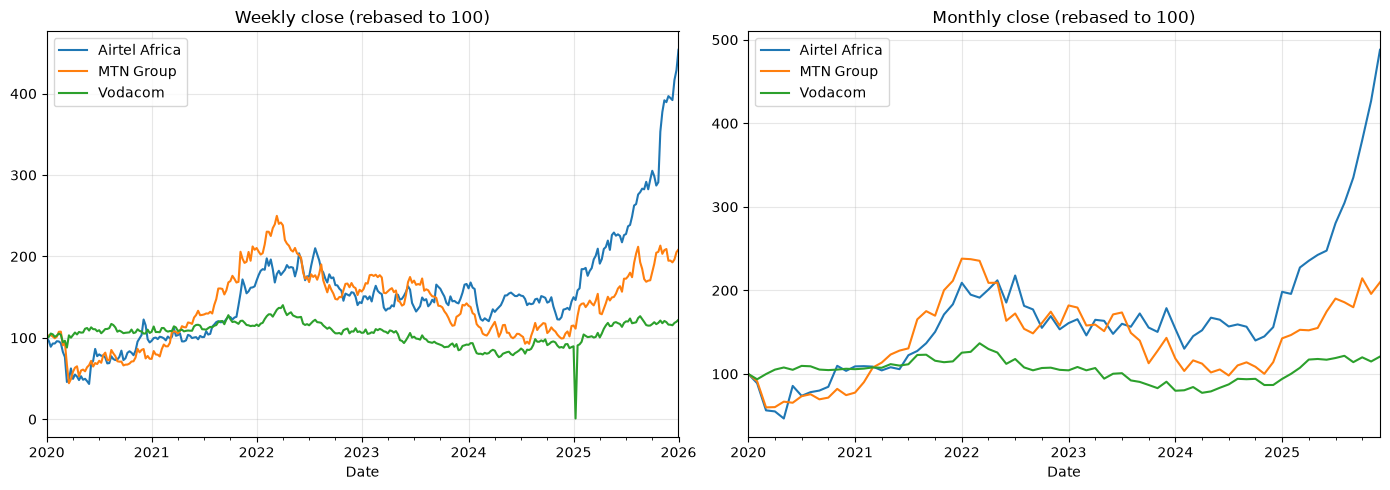

Average monthly return (%):
Airtel Africa    3.19
MTN Group        1.69
Vodacom          0.40
dtype: float64
Monthly volatility (std, %):
Airtel Africa    14.72
MTN Group        11.25
Vodacom           5.25
dtype: float64


In [5]:
weekly  = close.resample("W").last()
monthly = close.resample("ME").last()      # use "M" on older pandas versions

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=False)
(weekly / weekly.bfill().iloc[0] * 100).plot(ax=axes[0], title="Weekly close (rebased to 100)")
(monthly / monthly.bfill().iloc[0] * 100).plot(ax=axes[1], title="Monthly close (rebased to 100)")
plt.tight_layout(); plt.show()

monthly_returns = monthly.pct_change().dropna() * 100
print("Average monthly return (%):"); print(monthly_returns.mean().round(2))
print("Monthly volatility (std, %):"); print(monthly_returns.std().round(2))

## 5. Moving averages: 20-day and 200-day
The 20-day average shows short-term direction; the 200-day shows the long-term trend. When the 20-day crosses above the 200-day, traders call it a *golden cross*; below is a *death cross*.

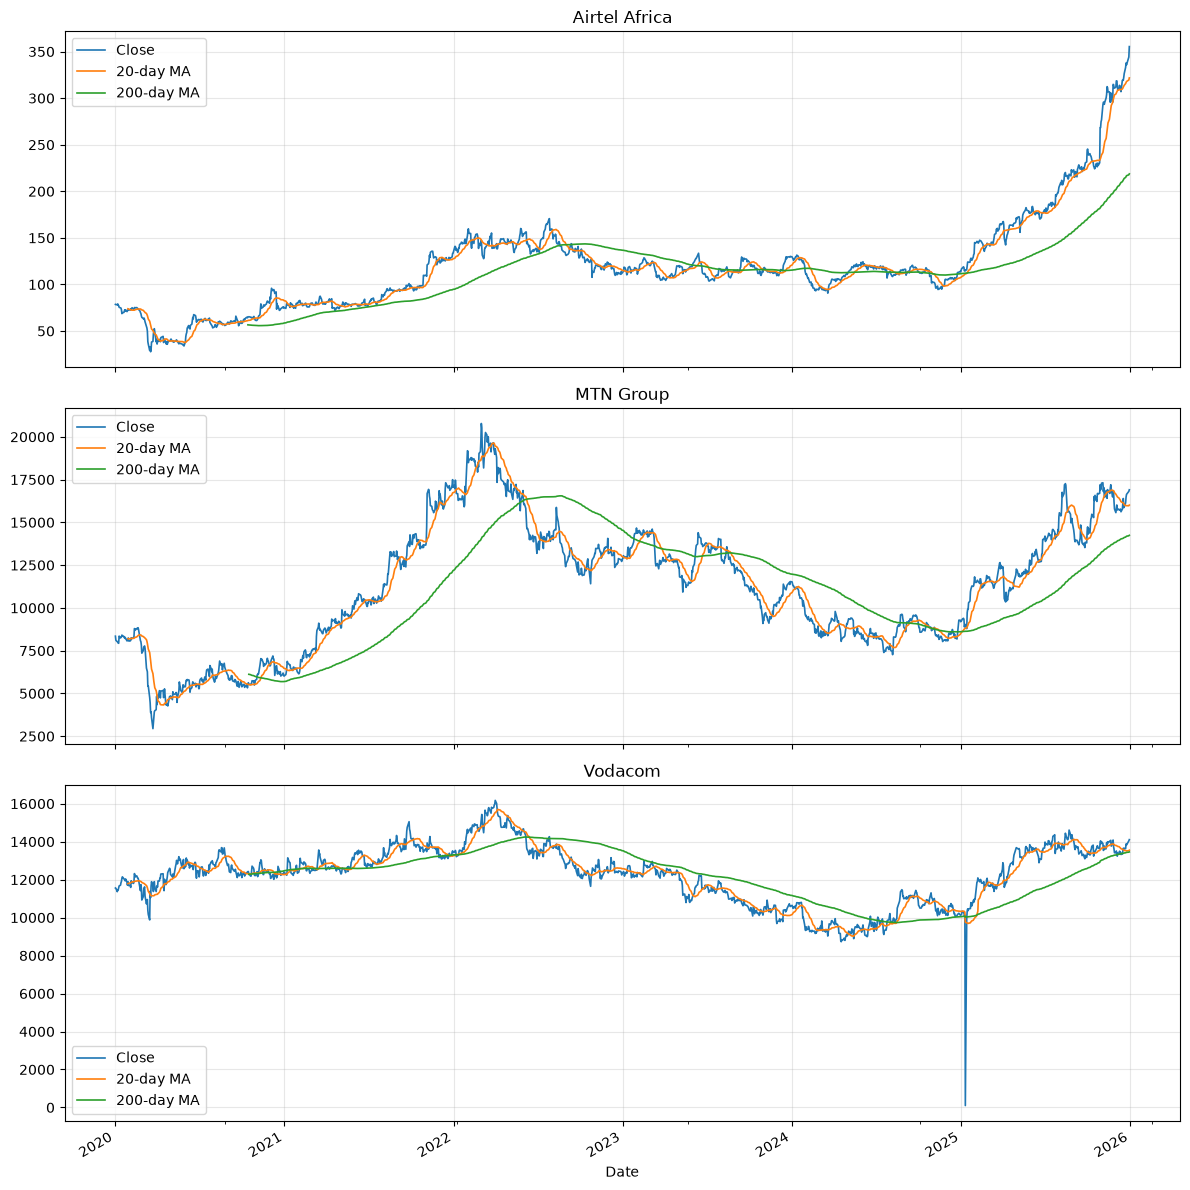

In [6]:
fig, axes = plt.subplots(len(frames), 1, figsize=(12, 4 * len(frames)), sharex=True)
for ax, (name, df) in zip(axes, frames.items()):
    ma = pd.DataFrame({
        "Close": df["Close"],
        "20-day MA": df["Close"].rolling(20).mean(),
        "200-day MA": df["Close"].rolling(200).mean(),
    })
    ma.plot(ax=ax, title=name, lw=1.2)
plt.tight_layout(); plt.show()

In [7]:
# Where does each stock end the period relative to its 200-day average?
for name, df in frames.items():
    last = df["Close"].iloc[-1]; ma200 = df["Close"].rolling(200).mean().iloc[-1]
    print(f"{name:14s} close vs 200-day MA: {(last/ma200 - 1)*100:+.1f}%")

Airtel Africa  close vs 200-day MA: +62.5%
MTN Group      close vs 200-day MA: +18.7%
Vodacom        close vs 200-day MA: +4.8%


## 6. Trading volume comparison

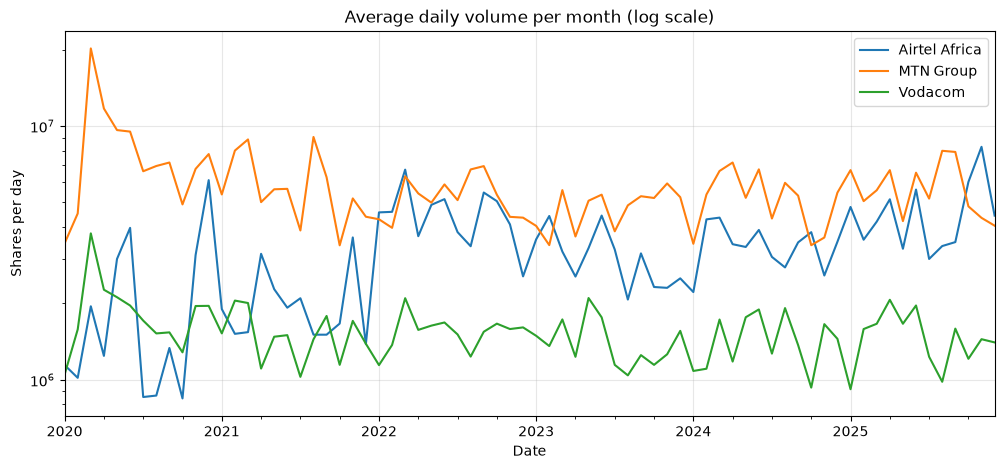

,Avg daily volume,Median daily volume,Peak day
Airtel Africa,3280655,2393012,82461685
MTN Group,5881375,4789886,82254233
Vodacom,1548444,1296895,11729490


In [8]:
volume = pd.DataFrame({name: df["Volume"] for name, df in frames.items()})

volume.resample("ME").mean().plot(logy=True, title="Average daily volume per month (log scale)")
plt.ylabel("Shares per day"); plt.show()

summary = pd.DataFrame({
    "Avg daily volume": volume.mean(),
    "Median daily volume": volume.median(),
    "Peak day": volume.max(),
}).round(0).astype(int)
summary

## 7. Local snapshot: TNM vs Airtel Malawi (MSE, Q3 2026)

yfinance has no feed for the Malawi Stock Exchange, so this section uses figures from the MSE *Quarterly Market Performance Report, Q3 2026* (July to September). It is a single-quarter summary, not a daily history, so no moving averages here.

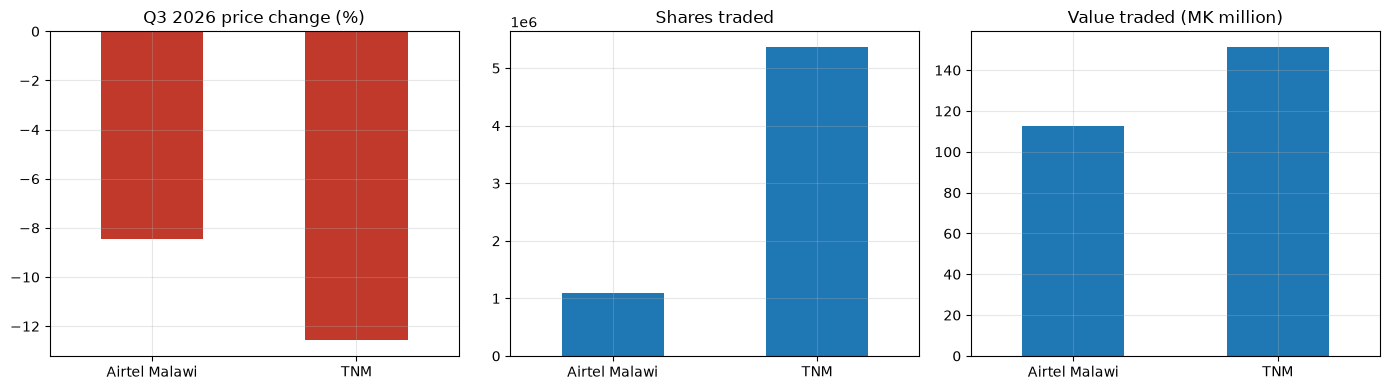

,Open (MK),Close (MK),Price change (%),Volume (shares),Value (MK),Trades,Avg price per share traded (MK)
Airtel Malawi,111.29,101.89,-8.45,1088106,1.126510e+08,409,103.53
TNM,29.17,25.50,-12.58,5370585,1.514504e+08,327,28.20


In [9]:
mse = pd.DataFrame({
    "Open (MK)":   [111.29, 29.17],
    "Close (MK)":  [101.89, 25.50],
    "Price change (%)": [-8.45, -12.58],
    "Volume (shares)":  [1_088_106, 5_370_585],
    "Value (MK)":       [112_650_993.34, 151_450_361.66],
    "Trades":           [409, 327],
}, index=["Airtel Malawi", "TNM"])
mse["Avg price per share traded (MK)"] = (mse["Value (MK)"] / mse["Volume (shares)"]).round(2)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
mse["Price change (%)"].plot.bar(ax=axes[0], color=["#c0392b"]*2, title="Q3 2026 price change (%)", rot=0)
mse["Volume (shares)"].plot.bar(ax=axes[1], title="Shares traded", rot=0)
mse["Value (MK)"].div(1e6).plot.bar(ax=axes[2], title="Value traded (MK million)", rot=0)
plt.tight_layout(); plt.show()
mse

## 8. Takeaways

*Fill these in after running the notebook with your own output.*

- **Trend:** which of the three stocks ended 2025 highest on the rebased chart?
- **Momentum:** which sits above its 200-day average?
- **Liquidity:** how large is the volume gap between the three?
- **Malawi:** TNM and Airtel Malawi both fell in Q3 2026 (-12.58% and -8.45%), part of a market-wide decline where the MASI lost 6.44%. TNM traded more shares but at a far lower price per share, so Airtel Malawi still traded nearly as much by value.

**Limitations:** the main analysis uses parent or regional peers rather than the Malawi-listed shares; local figures come from a single quarterly report.